# DiploMind: fast QLoRA adapters on Llama 3.1 8B Instruct (Unsloth)

Trains one LoRA adapter per run on a 4-bit **Llama 3.1 8B Instruct**:

| Adapter | Training set | Learns |
|---|---|---|
| `lang_urdish` | all Urdish outputs, every depth | to write in Urdish |
| `depth_easy` | all easy outputs, every language | to explain at beginner level |

**Speed-ups compared with the first notebook**
- **Unsloth**: hand-written GPU kernels and a loss that never builds the full 128k-vocabulary table: about 2× faster and far less memory, so the whole model fits on **one** T4 (no slow splitting over two GPUs).
- Pre-quantised 4-bit model (`unsloth/Meta-Llama-3.1-8B-Instruct-bnb-4bit`): no quantising at load time, not gated.
- `MAX_LEN` 2048 (long news inputs are cut, target outputs never), **1 epoch**, no LoRA dropout (Unsloth's fast path), 8-bit optimizer.
- Validation on a 60-row subset only, a few times per run.
- **Time guard**: training stops and saves itself before Kaggle's 12-hour limit; re-running resumes from the last checkpoint.
- After 10 steps it prints the measured speed and the projected total time.

**Kaggle setup**: Accelerator **GPU T4 x2** (one is used) or P100, **Internet on**, Add Input → your `diplomind_dataset`. Set `ADAPTER` in section 2, then **Save Version → Save & Run All**.

## 1. Install Unsloth
If a later cell fails with an import error right after installing, use **Run → Restart & clear outputs** and run again from section 2 (the install stays).

In [3]:
!pip install -q unsloth


[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## 2. Settings

In [4]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0"          # Unsloth trains on one GPU; must be set before torch loads
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
import unsloth                                     # must be imported before transformers
from unsloth import FastLanguageModel, is_bfloat16_supported
import glob, math, json, random, time
import torch, pandas as pd

ADAPTER = "lang_urdish"        # "lang_urdish" or "depth_easy" (any folder name in training_sets works)
MODEL_ID = "unsloth/Meta-Llama-3.1-8B-Instruct-bnb-4bit"
# Llama 3.2 3B baseline (about 2.5x faster): "unsloth/Llama-3.2-3B-Instruct-bnb-4bit"

DATA_ROOT = (glob.glob("/kaggle/input/**/training_sets", recursive=True) or ["training_sets"])[0]
OUT_ROOT  = "/kaggle/working" if os.path.isdir("/kaggle/working") else "."

MAX_LEN      = 3072    # tokens per example
EPOCHS       = 2
LR           = 2e-4
LORA_R       = 16
LORA_ALPHA   = 32
BATCH        = 1
GRAD_ACCUM   = 8        # effective batch = 8
EVAL_ROWS    = 60       # validation subset used during training
EVAL_EVERY   = 50       # steps
SAVE_EVERY   = 25       # steps (checkpoint for resuming)
TIME_LIMIT_H = 10.5     # stop and save before Kaggle's 12 h limit
SEED         = 42

SYSTEM = "You are DiploMind, an assistant that explains news and international affairs to Pakistani readers."

TAG = ADAPTER + ("" if "8B" in MODEL_ID else "_" + MODEL_ID.split("/")[-1].split("-Instruct")[0].lower())
OUT_DIR  = os.path.join(OUT_ROOT, "adapters", TAG)
CKPT_DIR = os.path.join(OUT_ROOT, "checkpoints", TAG)
random.seed(SEED); torch.manual_seed(SEED)
print("Model:", MODEL_ID, "| adapter:", TAG)
print("Data :", os.path.join(DATA_ROOT, ADAPTER))
print("GPU  :", torch.cuda.get_device_name(0), "| bf16:", is_bfloat16_supported())

NotImplementedError: Unsloth: nvidia-smi sees NVIDIA RTX A4000 but torch.cuda.is_available() is False (torch 2.14.1+cpu, CUDA_VISIBLE_DEVICES='0'). PyTorch likely does not match this machine; reinstall it for c:\Program Files\Python313\python.exe per https://github.com/unslothai/unsloth#-install

## 3. Load the model (4-bit) and add LoRA

In [ ]:
model, tok = FastLanguageModel.from_pretrained(MODEL_ID, max_seq_length=MAX_LEN, dtype=None, load_in_4bit=True)
model = FastLanguageModel.get_peft_model(
    model, r=LORA_R, lora_alpha=LORA_ALPHA, lora_dropout=0, bias="none",
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"],
    use_gradient_checkpointing="unsloth", random_state=SEED,
)
if tok.pad_token is None or tok.pad_token == tok.eos_token:
    tok.pad_token = "<|finetune_right_pad_id|>" if "<|finetune_right_pad_id|>" in tok.get_vocab() else tok.eos_token
tok.padding_side = "right"
model.print_trainable_parameters()
print(f"GPU memory used: {torch.cuda.memory_allocated() / 1e9:.1f} GB")

==((====))==  Unsloth 2026.10.7: Fast Llama patching. Transformers: 5.16.1.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.562 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu128. CUDA: 7.5. CUDA Toolkit: 12.8. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.35. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


/usr/local/lib/python3.13/dist-packages/huggingface_hub/constants.py:299: FutureWarning: The `HF_HUB_ENABLE_HF_TRANSFER` environment variable is deprecated as 'hf_transfer' is not used anymore. Please use `HF_XET_HIGH_PERFORMANCE` instead to enable high performance transfer with Xet. Visit https://huggingface.co/docs/huggingface_hub/package_reference/environment_variables#hfxethighperformance for more details.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/huggingface_hub/constants.py:299: FutureWarning: The `HF_HUB_ENABLE_HF_TRANSFER` environment variable is deprecated as 'hf_transfer' is not used anymore. Please use `HF_XET_HIGH_PERFORMANCE` instead to enable high performance transfer with Xet. Visit https://huggingface.co/docs/huggingface_hub/package_reference/environment_variables#hfxethighperformance for more details.
  warnings.warn(


Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

Unsloth: Will load unsloth/Meta-Llama-3.1-8B-Instruct-bnb-4bit as a legacy tokenizer.
Unsloth 2026.10.7 patched 32 layers with 32 QKV layers, 32 O layers and 32 MLP layers.


trainable params: 41,943,040 || all params: 8,072,204,288 || trainable%: 0.5196
GPU memory used: 5.9 GB


## 4. Load the data
Each row becomes a chat: system message, user turn (instruction + news), assistant turn (the target explanation). **Loss is computed only on the assistant turn.** Use the same format at inference time (section 8).

In [ ]:
def load(split):
    return pd.read_csv(os.path.join(DATA_ROOT, ADAPTER, f"{split}.csv")).fillna("").to_dict("records")

def user_text(instruction, news):
    return f"{instruction}\n\nNews:\n{news}"

def prompt_ids(instruction, news):
    msgs = [{"role": "system", "content": SYSTEM}, {"role": "user", "content": user_text(instruction, news)}]
    text = tok.apply_chat_template(msgs, add_generation_prompt=True, tokenize=False)
    return tok(text, add_special_tokens=False)["input_ids"]

EOT = "<|eot_id|>" if "<|eot_id|>" in tok.get_vocab() else tok.eos_token

def encode(row):
    """Prompt + answer ids; labels masked on the prompt. The news is cut to fit MAX_LEN, the answer never."""
    answer = tok(row["output"] + EOT, add_special_tokens=False)["input_ids"]
    news_ids = tok(row["input"], add_special_tokens=False)["input_ids"]
    budget = MAX_LEN - len(answer) - len(prompt_ids(row["instruction"], ""))
    cut = budget < len(news_ids)
    if cut:
        news_ids = news_ids[:max(budget, 0)]
    p = prompt_ids(row["instruction"], tok.decode(news_ids))
    return {"input_ids": (p + answer)[:MAX_LEN], "labels": ([-100] * len(p) + answer)[:MAX_LEN], "cut": cut}

data = {s: [encode(r) for r in load(s)] for s in ("train", "val", "test")}
for s, rows in data.items():
    lens = sorted(len(r["input_ids"]) for r in rows)
    print(f"{s:5}: {len(rows):5} rows | tokens median {lens[len(lens)//2]}, p95 {lens[int(len(lens)*.95)]}, "
          f"max {lens[-1]} | news cut: {sum(r['cut'] for r in rows)} | total {sum(lens)/1e6:.2f}M tokens")

Ignoring clean_up_tokenization_spaces=True for BPE tokenizer TokenizersBackend. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


train:  1398 rows | tokens median 1185, p95 2806, max 3072 | news cut: 12 | total 2.00M tokens
val  :   174 rows | tokens median 1333, p95 2478, max 3072 | news cut: 2 | total 0.25M tokens
test :   177 rows | tokens median 1053, p95 2792, max 3058 | news cut: 0 | total 0.24M tokens


## 5. Train (speed report after 10 steps, time guard, resumable)

In [ ]:
import inspect
from transformers import Trainer, TrainingArguments, DataCollatorForSeq2Seq, TrainerCallback
from datasets import Dataset

cols = ["input_ids", "labels"]
train_ds = Dataset.from_list([{k: r[k] for k in cols} for r in data["train"]])
val_rows = data["val"][:]
random.Random(SEED).shuffle(val_rows)
val_ds = Dataset.from_list([{k: r[k] for k in cols} for r in val_rows[:EVAL_ROWS]])
collator = DataCollatorForSeq2Seq(tok, padding=True, label_pad_token_id=-100, pad_to_multiple_of=8)

class SpeedAndTimeGuard(TrainerCallback):
    """Prints measured speed and projected time after 10 steps; stops and saves before the time limit."""
    def on_train_begin(self, args, state, control, **kw):
        self.t0, self.s0 = time.time(), state.global_step
    def on_step_end(self, args, state, control, **kw):
        done = state.global_step - self.s0
        elapsed = time.time() - self.t0
        if done == 10:
            per_step = elapsed / done
            left = (state.max_steps - state.global_step) * per_step
            print(f"\n[speed] {per_step:.0f} s per step -> about {left / 3600:.1f} h left for {state.max_steps} steps")
        if elapsed > TIME_LIMIT_H * 3600:
            print(f"\n[time guard] {TIME_LIMIT_H} h reached at step {state.global_step}: saving and stopping. "
                  "Re-run the notebook to continue from this checkpoint.")
            control.should_save = True
            control.should_training_stop = True
        return control

steps_total = math.ceil(len(train_ds) / (BATCH * GRAD_ACCUM)) * EPOCHS
kw = dict(
    output_dir=CKPT_DIR,
    num_train_epochs=EPOCHS,
    per_device_train_batch_size=BATCH,
    per_device_eval_batch_size=BATCH,
    gradient_accumulation_steps=GRAD_ACCUM,
    learning_rate=LR,
    lr_scheduler_type="cosine",
    warmup_steps=max(1, int(0.05 * steps_total)),
    weight_decay=0.0,
    optim="adamw_8bit",
    bf16=is_bfloat16_supported(), fp16=not is_bfloat16_supported(),
    max_grad_norm=0.3,
    logging_steps=5,
    eval_strategy="steps", eval_steps=EVAL_EVERY,
    save_strategy="steps", save_steps=SAVE_EVERY, save_total_limit=2,
    report_to="none",
    seed=SEED,
    dataloader_num_workers=2,
)
valid = set(inspect.signature(TrainingArguments.__init__).parameters)
if "eval_strategy" not in valid and "evaluation_strategy" in valid:
    kw["evaluation_strategy"] = kw.pop("eval_strategy")
skipped = [k for k in kw if k not in valid]
if skipped:
    print("Skipped (not supported by this transformers version):", skipped)
args = TrainingArguments(**{k: v for k, v in kw.items() if k in valid})

trainer = Trainer(model=model, args=args, train_dataset=train_ds, eval_dataset=val_ds,
                  data_collator=collator, callbacks=[SpeedAndTimeGuard()])

last = sorted(glob.glob(os.path.join(CKPT_DIR, "checkpoint-*")), key=lambda p: int(p.split("-")[-1]))
print(f"{steps_total} optimizer steps | resuming from {last[-1]}" if last else f"{steps_total} optimizer steps")
t0 = time.time()
result = trainer.train(resume_from_checkpoint=last[-1] if last else None)
FINISHED = trainer.state.global_step >= trainer.state.max_steps
print(f"Training time this session: {(time.time() - t0) / 3600:.2f} h | finished: {FINISHED}")

==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 1,398 | Num Epochs = 2 | Total steps = 350
O^O/ \_/ \    Batch size per device = 1 | Gradient accumulation steps = 8
\        /    Data Parallel GPUs = 1 | Total batch size (1 x 8 x 1) = 8
 "-____-"     Trainable parameters = 41,943,040 of 8,072,204,288 (0.52% trained)


350 optimizer steps
Unsloth: Will smartly offload gradients to save VRAM!
Unsloth: Double buffering enabled (parallel H2D + compute) for backward pass.


Step,Training Loss,Validation Loss
50,0.956559,0.901375
100,0.736021,0.833114
150,0.723245,0.797090
200,0.437482,0.821028
250,0.385851,0.813516
300,0.415978,0.809842
350,0.377980,0.808021



[speed] 39 s per step -> about 3.7 h left for 350 steps


Unsloth: Restored added_tokens_decoder metadata in /kaggle/working/checkpoints/lang_urdish/checkpoint-25/tokenizer_config.json.
Unsloth: Restored added_tokens_decoder metadata in /kaggle/working/checkpoints/lang_urdish/checkpoint-50/tokenizer_config.json.
Unsloth: Restored added_tokens_decoder metadata in /kaggle/working/checkpoints/lang_urdish/checkpoint-75/tokenizer_config.json.
Unsloth: Restored added_tokens_decoder metadata in /kaggle/working/checkpoints/lang_urdish/checkpoint-100/tokenizer_config.json.
Unsloth: Restored added_tokens_decoder metadata in /kaggle/working/checkpoints/lang_urdish/checkpoint-125/tokenizer_config.json.
Unsloth: Restored added_tokens_decoder metadata in /kaggle/working/checkpoints/lang_urdish/checkpoint-150/tokenizer_config.json.
Unsloth: Restored added_tokens_decoder metadata in /kaggle/working/checkpoints/lang_urdish/checkpoint-175/tokenizer_config.json.
Unsloth: Restored added_tokens_decoder metadata in /kaggle/working/checkpoints/lang_urdish/checkpoin

Training time this session: 3.96 h | finished: True


## 6. Save the adapter and loss curve

Unsloth: Restored added_tokens_decoder metadata in /kaggle/working/adapters/lang_urdish/tokenizer_config.json.


 step  eval_loss
   50   0.901375
  100   0.833114
  150   0.797090
  200   0.821028
  250   0.813516
  300   0.809842
  350   0.808021


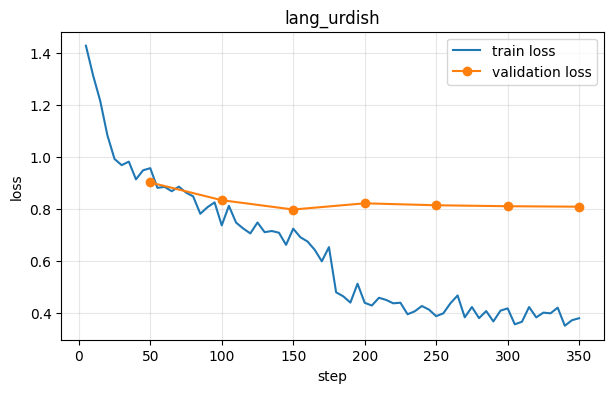

Saved adapter to /kaggle/working/adapters/lang_urdish


In [ ]:
model.save_pretrained(OUT_DIR)
tok.save_pretrained(OUT_DIR)
json.dump({"adapter": ADAPTER, "base_model": MODEL_ID, "system": SYSTEM, "max_len": MAX_LEN,
           "lora_r": LORA_R, "lora_alpha": LORA_ALPHA, "epochs": EPOCHS, "lr": LR,
           "steps": trainer.state.global_step, "finished": FINISHED,
           "train_rows": len(data["train"]), "trained_with": "unsloth"},
          open(os.path.join(OUT_DIR, "diplomind_config.json"), "w"), indent=1)

hist = pd.DataFrame(trainer.state.log_history)
hist.to_csv(os.path.join(OUT_DIR, "log_history.csv"), index=False)
tr = hist.dropna(subset=["loss"])[["step", "loss"]] if "loss" in hist else pd.DataFrame(columns=["step", "loss"])
ev = hist.dropna(subset=["eval_loss"])[["step", "eval_loss"]] if "eval_loss" in hist else pd.DataFrame(columns=["step", "eval_loss"])
print(ev.to_string(index=False))

import matplotlib.pyplot as plt
plt.figure(figsize=(7, 4))
plt.plot(tr.step, tr.loss, label="train loss")
plt.plot(ev.step, ev.eval_loss, "o-", label="validation loss")
plt.xlabel("step"); plt.ylabel("loss"); plt.title(TAG); plt.legend(); plt.grid(alpha=.3)
plt.savefig(os.path.join(OUT_DIR, "loss.png"), dpi=120, bbox_inches="tight"); plt.show()
print("Saved adapter to", OUT_DIR)

## 7. Test loss: base model vs adapter (60 test rows)
The test articles are the same for every adapter, so these numbers are comparable. Lower is better.

In [ ]:
test_rows = data["test"][:]
random.Random(SEED).shuffle(test_rows)
test_ds = Dataset.from_list([{k: r[k] for k in cols} for r in test_rows[:60]])
with_adapter = trainer.evaluate(test_ds, metric_key_prefix="test")["test_loss"]
with model.disable_adapter():
    base = trainer.evaluate(test_ds, metric_key_prefix="test")["test_loss"]
print(f"Test loss  base: {base:.3f} (perplexity {math.exp(base):.1f})")
print(f"Test loss  {TAG}: {with_adapter:.3f} (perplexity {math.exp(with_adapter):.1f})")
json.dump({"test_loss_base": base, "test_loss_adapter": with_adapter, "test_rows": len(test_ds)},
          open(os.path.join(OUT_DIR, "test_loss.json"), "w"), indent=1)

Training Loss,Validation Loss,Step
0.377980,0.853969,350


Training Loss,Validation Loss,Step
0.377980,1.484565,350


Test loss  base: 1.485 (perplexity 4.4)
Test loss  lang_urdish: 0.854 (perplexity 2.3)


## 8. Generate: base vs adapter on 3 test articles
This is the inference format to use in DiploMind: same system message, user turn = `instruction + "\n\nNews:\n" + text`.

In [ ]:
FastLanguageModel.for_inference(model)          # Unsloth's 2x faster generation
raw_test = load("test")
random.Random(1).shuffle(raw_test)

def generate(instruction, news, max_new_tokens=1024):
    ids = torch.tensor([prompt_ids(instruction, news)], device="cuda")
    with torch.no_grad():
        out = model.generate(input_ids=ids, max_new_tokens=max_new_tokens, do_sample=False, repetition_penalty=1.05,
                             pad_token_id=tok.pad_token_id, eos_token_id=tok.convert_tokens_to_ids(EOT))
    return tok.decode(out[0, ids.shape[1]:], skip_special_tokens=True).strip()

samples = []
for r in raw_test[:3]:
    news = tok.decode(tok(r["input"], add_special_tokens=False)["input_ids"][:1200])
    tuned = generate(r["instruction"], news)
    with model.disable_adapter():
        base_out = generate(r["instruction"], news)
    samples.append({"instruction": r["instruction"], "language": r["language"], "depth": r["depth"],
                    "url": r["url"], "reference": r["output"], "base": base_out, "adapter": tuned})
    print("=" * 100, f"\n[{r['language']} / {r['depth']}] {r['url']}")
    print("\n--- BASE ---\n", base_out[:1200])
    print("\n--- ADAPTER ---\n", tuned[:1200])
    print("\n--- REFERENCE ---\n", r["output"][:1200])
pd.DataFrame(samples).to_csv(os.path.join(OUT_DIR, "samples.csv"), index=False, encoding="utf-8-sig")

Both `max_new_tokens` (=1024) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=1024) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=1024) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[urdish / easy] https://www.dawn.com/news/2023712/pakistan-expands-unesco-world-heritage-tentative-list

--- BASE ---
 Aap ko yeh news samjhani hai jo Pakistan ke liye bahut hi achhi hai. 

Pakistan ne apne UNESCO World Heritage tentative list mein se 25 se 37 properties tak badal diya hai. Yeh 12 naye cultural aur heritage sites hain jo Pakistan ki tarikh aur sanskriti ki legacy ko strong karne ke liye hain.

Yeh naye properties mein Archaeological Complex of Gor Khatri, Bazira-Barikot, Bhamala Buddhist Complex, Sethi House, Mai Qamro Mosque, Pharwala Fort, Rawat Fort, Tomb of Sultan Muqarrab Khan, Kot Diji Fort, Naukot Fort, Umerkot Fort aur Kalasha Valley Cultural Landscape shamil hain.

Yeh properties UNESCO records ke anusaar teen phase mein add kiye gaye hain. Kalasha Valley Cultural Landscape ko March 9 ko, Kot Diji, Naukot aur Umerkot forts ko March 18 ko, aur baki 8 properties ko May 11 ko add kiya gaya hai.

Federal Minister for National Heritage and Culture Aurangzeb Khan Kh

Both `max_new_tokens` (=1024) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=1024) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[urdish / easy] https://www.bbc.com/urdu/articles/c8d0ln7lzj1o

--- BASE ---
 یہ خبر کے بارے میں ہے کہ کیا پاکستان میں مہنگائی کم ہوئی ہے یا نہیں۔

**مہنگائی کیا ہے؟**
مہنگائی وہ صورت حال ہوتی ہے جب کسی ملک میں اشیا کی قیمتیں بڑھ جاتی ہیں اور لوگوں کو خریدنے کے لیے زیادہ پیسے دینے پڑتے ہیں۔

**اسلام آباد میں ایک خاتون کا کہنا**
ایک خاتون نے بتایا کہ وہ اپنے گھر میں گھی، چینی اور دیگر اشیا خریدتی ہیں۔ انھوں نے کہا کہ اب ان اشیا کی قیمتیں بڑھ گئی ہیں اور انھیں لگتا ہے کہ ایک ہزار روپے کا نوٹ سو روپے جیسا ہے۔

**وزیراعظم شہباز شریف کا دعویٰ**
وزیراعظم شہباز شریف کہتے ہیں کہ پاکستان میں اقتصادی طور پر مستحکم ہوا ہے اور روپے کی قدر برقرار ہے۔ انھوں نے کہا کہ ملک میں زراعت، صنعت، کان کنی، مصنوعی ذہانت اور آئی ٹی جیسے شعبوں میں 'اڑان بھرنے والا ہے۔'

**کاروباری طبقہ کی گلہ**
لیکن وفاقی چیمبر آف کامرس کے صدر ایس ایم تنویر کہتے ہیں کہ پچھلے ڈیڑھ سے دو سال میں 140 سے 150 بڑے ٹیکسٹائل یونٹ بند ہو گئے ہیں اور یہ یونٹس بڑے پیمانے پر ملازمتیں دیتے تھے۔ انھوں نے وزیراعظم سے اپیل کی ہے کہ جلد فیصلے کر

Both `max_new_tokens` (=1024) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[urdish / hard] https://www.dawn.com/news/2037237/lawmakers-govt-differ-over-discos-privatisation

--- BASE ---
 اسٹیٹ منیجری کے حوالے سے ایک اہم معاملہ میں، وفاقی حکومت نے پاور ڈسٹریبیوشن کمپنیوں (ڈیسکو) کی خصوصی کروڑی کے حوالے سے ایک اہم معاملہ میں، وفاقی حکومت نے پاور ڈسٹریبیوشن کمپنیوں (ڈیسکو) کی خصوصی کروڑی کے حوالے سے ایک اہم معاملہ میں، وفاقی حکومت نے پاور ڈسٹریبیوشن کمپنیوں (ڈیسکو) کی خصوصی کروڑی کے حوالے سے ایک اہم معاملہ میں، وفاقی حکومت نے پاور ڈسٹریبیوشن کمپنیوں (ڈیسکو) کی خصوصی کروڑی کے حوالے سے ایک اہم معاملہ میں، وفاقی حکومت نے پاور ڈسٹریبیوشن کمپنیوں (ڈیسکو) کی خصوصی کروڑی کے حوالے سے ایک اہم معاملہ میں، وفاقی حکومت نے پاور ڈسٹریبیوشن کمپنیوں (ڈیسکو) کی خصوصی کروڑی کے حوالے سے ایک اہم معاملہ میں، وفاقی حکومت نے پاور ڈسٹریبیوشن کمپنیوں (ڈیسکو) کی خصوصی کروڑی کے حوالے سے ایک اہم معاملہ میں، وفاقی حکومت نے پاور ڈسٹریبیوشن کمپنیوں (ڈیسکو) کی خصوصی کروڑی کے حوالے سے ایک اہم معاملہ میں، وفاقی حکومت نے پاور ڈسٹریبیوشن کمپنیوں (ڈیسکو) کی خصوصی کروڑی کے حوالے سے ایک اہم معاملہ م

## 9. Package the adapter
The adapter is a standard PEFT adapter (~170 MB): it loads with plain `transformers` + `peft` on top of Llama 3.1 8B Instruct, no Unsloth needed.

In [ ]:
import shutil
zip_path = shutil.make_archive(os.path.join(OUT_ROOT, f"adapter_{TAG}"), "zip", OUT_DIR)
if FINISHED:
    shutil.rmtree(CKPT_DIR, ignore_errors=True)   # keep checkpoints only if training must be resumed
print("Packaged:", zip_path, f"({os.path.getsize(zip_path) / 1e6:.0f} MB)", "| finished:", FINISHED)

Packaged: /kaggle/working/adapter_lang_urdish.zip (158 MB) | finished: True
